In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

import seaborn as sns

In [7]:
df_data = pd.read_csv('../data/processed/encoded_student_risk.csv')
df_data.columns

Index(['person_id', 'age', 'gender', 'nationality', 'first_generation',
       'disability_status', 'scholarship_holder', 'tuition_up_to_date',
       'part_time_job', 'weekly_work_hours', 'semester',
       'international_student', 'admission_grade',
       'previous_qualification_grade', 'units_enrolled', 'units_passed',
       'units_failed', 'gpa_semester_1', 'gpa_semester_2', 'attendance_rate',
       'assignments_submitted_rate', 'library_visits_per_month',
       'lms_logins_per_week', 'extracurricular_activities', 'missed_deadlines',
       'stress_level', 'mental_health_support', 'satisfaction_score',
       'commute_time_mins', 'sleep_hours', 'dropout', 'course_type_Business',
       'course_type_Health Sciences', 'course_type_Law & Social Sciences',
       'course_type_STEM', 'study_mode_Online', 'study_mode_Part-time',
       'family_income_level_Low', 'family_income_level_Middle'],
      dtype='str')

In [10]:

cols_pillar1 = [
    # Demographics & Family Context
    "age",
    "gender",
    "first_generation",
    "international_student",
    "disability_status",
    "family_income_level_Low",
    "family_income_level_Middle",
    # Prior Academic Record & Program
    "admission_grade",
    "previous_qualification_grade",
    "semester",  # Added: academic journey milestone
    "course_type_Business",  # Moved from Pillar 2
    "course_type_Health Sciences",  # Moved from Pillar 2
    "course_type_Law & Social Sciences",  # Moved from Pillar 2
    "course_type_STEM",  # Moved from Pillar 2
    # External Time & Financial Commitments
    "commute_time_mins",
    "part_time_job",
    "weekly_work_hours",
    'dropout'  # Moved from Pillar 2 to pair with part_time_job
]

df_pillar1 = df_data[cols_pillar1]
df_pillar1

,age,gender,first_generation,international_student,disability_status,family_income_level_Low,family_income_level_Middle,admission_grade,previous_qualification_grade,semester,course_type_Business,course_type_Health Sciences,course_type_Law & Social Sciences,course_type_STEM,commute_time_mins,part_time_job,weekly_work_hours,dropout
0,23,0,0,0,0,1,0,164.6,165.1,7,0,0,0,1,37,1,24,0
1,18,1,1,1,1,0,0,175.2,164.1,6,0,0,0,0,15,0,0,1
2,24,1,0,0,0,0,0,126.0,179.3,3,0,0,0,0,4,1,16,0
3,25,2,0,0,1,0,1,75.5,161.9,1,1,0,0,0,10,0,0,0
4,15,2,0,0,0,1,0,89.0,101.8,2,0,1,0,0,24,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,25,2,0,0,0,0,1,108.3,130.1,8,0,0,1,0,11,1,18,0
99996,24,2,0,0,1,0,1,118.9,132.1,1,0,0,0,1,21,1,15,1
99997,27,2,0,0,0,0,1,150.1,103.3,3,0,0,0,0,29,1,26,0
99998,21,0,0,0,0,0,0,168.0,149.2,2,0,0,0,0,43,0,0,0


## Logistic Regression

In [12]:
target = 'dropout'
print(df_data[target].value_counts(normalize=True))

X = df_data.drop(columns=[target, 'person_id', 'nationality'])
y = df_data[target]
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

dropout
0    0.67996
1    0.32004
Name: proportion, dtype: float64


              precision    recall  f1-score   support

           0       0.91      0.82      0.86     13599
           1       0.68      0.82      0.75      6401

    accuracy                           0.82     20000
   macro avg       0.79      0.82      0.80     20000
weighted avg       0.84      0.82      0.82     20000

ROC AUC: 0.903167223106168


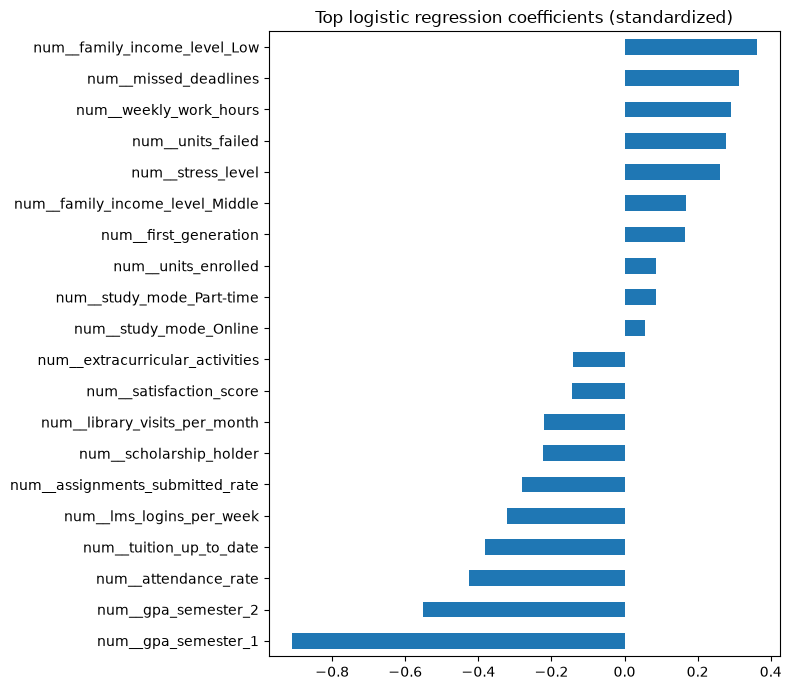

Intercept: -0.6411394951791437


,feature,coefficient,odds_ratio
0,num__gpa_semester_1,-0.909885,0.402570
1,num__gpa_semester_2,-0.551111,0.576309
2,num__attendance_rate,-0.424590,0.654038
3,num__tuition_up_to_date,-0.383048,0.681780
4,num__family_income_level_Low,0.361817,1.435936
5,num__lms_logins_per_week,-0.320455,0.725819
6,num__missed_deadlines,0.311956,1.366094
7,num__weekly_work_hours,0.290712,1.337379
8,num__assignments_submitted_rate,-0.279969,0.755807
9,num__units_failed,0.277883,1.320332


In [13]:
preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])

log_reg = Pipeline([
    ('prep', preprocess),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print('ROC AUC:', roc_auc_score(y_test, y_prob))


names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['clf'].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot.barh(figsize=(8, 7), title='Top logistic regression coefficients (standardized)')
plt.tight_layout(); plt.show()
coef_df = pd.DataFrame({
    'feature': names,
    'coefficient': log_reg.named_steps['clf'].coef_[0],
})
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])
coef_df = coef_df.reindex(coef_df['coefficient'].abs().sort_values(ascending=False).index).reset_index(drop=True)
print('Intercept:', log_reg.named_steps['clf'].intercept_[0])
with pd.option_context('display.max_rows', None):
    display(coef_df)

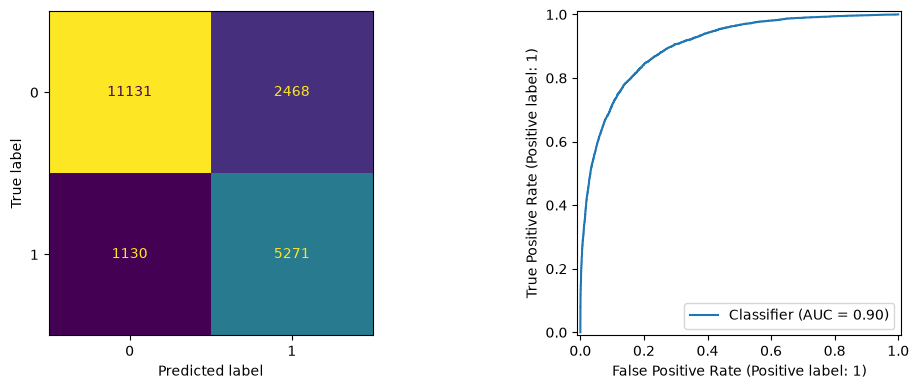

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
plt.tight_layout(); plt.show()

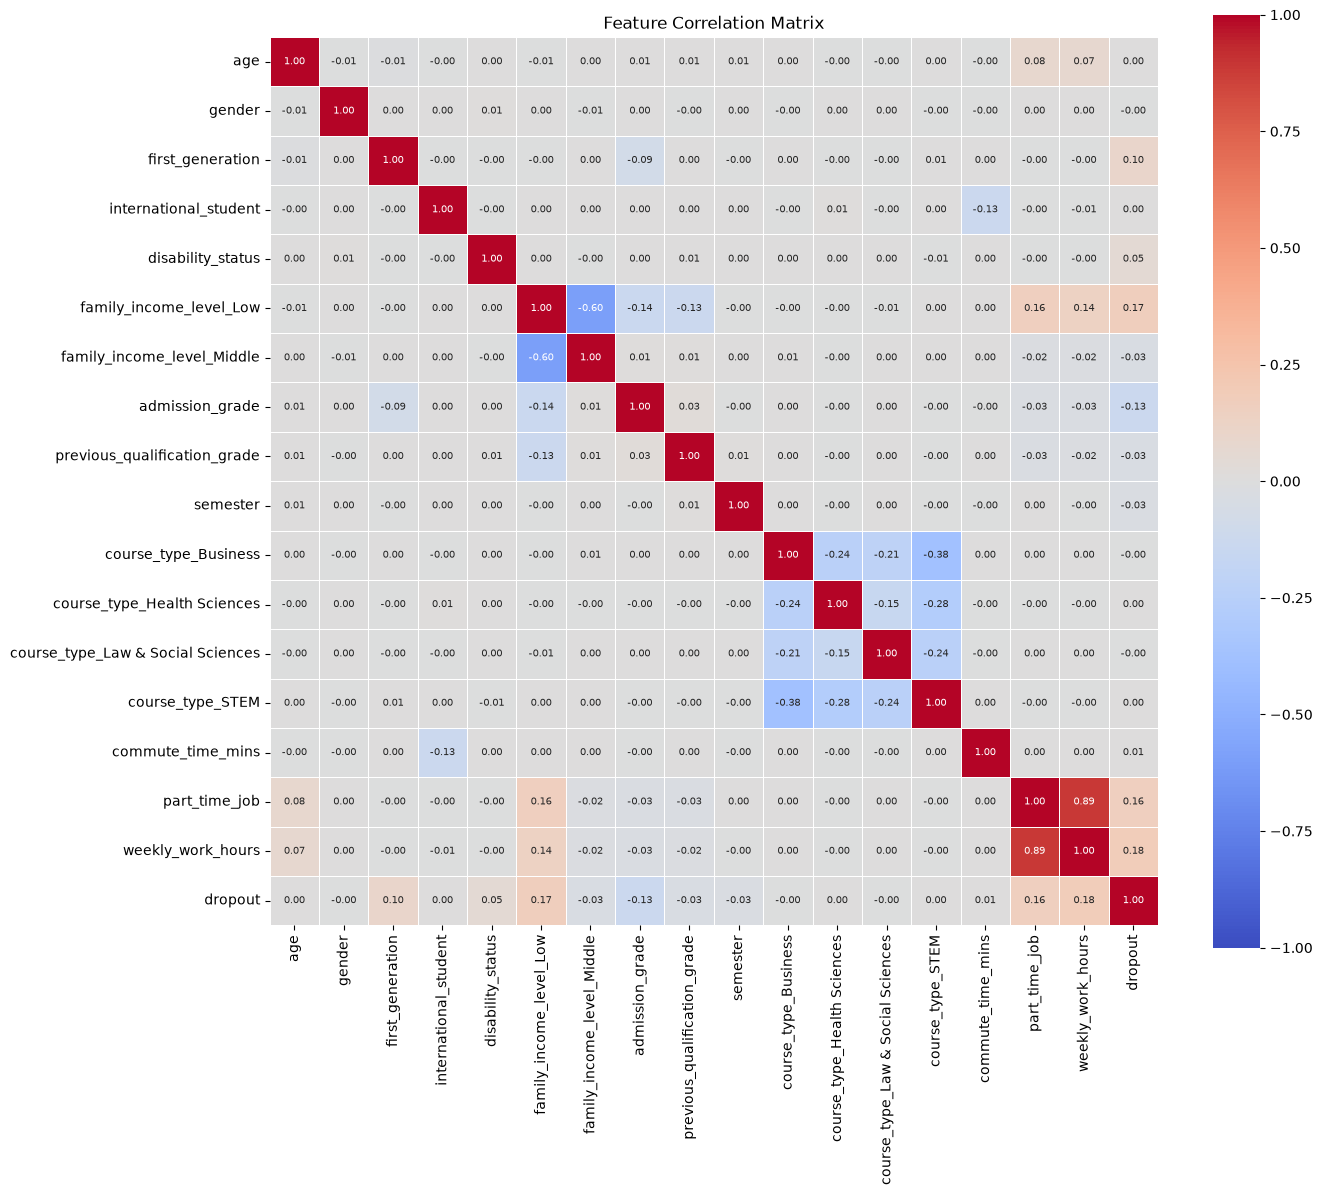

In [17]:
corr = df_pillar1.select_dtypes(include="number").corr()
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    square=True,
    linewidths=0.5,
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()